# 1.0 Method #

In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

[codecarbon WARNING @ 19:24:03] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [ ]:
TEXT_COL = "sentence"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]

### 1.1 Negative Correlation Based Asymmetry Testing

In [3]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

### 1.2 Distribution distance based differentiation testing

### 1.2 All pairwise cosine similarity

In [4]:
def calculate_pairwise_cosine_distribution(embeddings):
    scores = []

    for i in range(len(embeddings)):
        for j in range(i + 1, len(embeddings)):
            sim = torch.nn.functional.cosine_similarity(
                embeddings[i],
                embeddings[j],
                dim=0
            )
            scores.append(sim.item())

    return np.array(scores)

### 1.3 Pairwise Cosine simimarity (same label pairs)

In [5]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True
):

    labels = np.asarray(labels)
    unique_labels = np.unique(labels)

    all_scores = []#saving all results from different labels
    scores_by_label = {}#dictionary, saving results for each label

    for lab in unique_labels:
        idx = np.where(labels == lab)[0]

        # Need at least 2 samples to calculate pairwise cosine
        if len(idx) < 2:
            print(f"Label {lab}: skipped, only {len(idx)} sample")
            continue

        scores = []

        # Calculate cosine similarity only inside the same label
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                i = idx[a]
                j = idx[b]

                sim = torch.nn.functional.cosine_similarity(
                    embeddings[i],
                    embeddings[j],
                    dim=0
                )

                scores.append(sim.item())

        scores = np.array(scores)

        scores_by_label[lab] = scores
        all_scores.extend(scores)

        print(f"Label {lab}: {len(idx)} samples, {len(scores)} pairs")

    all_scores = np.array(all_scores)

    if return_by_label:
        return all_scores, scores_by_label
    else:
        return all_scores

### 1.4 Pairwise Cosine Similarity (Same and Different label)

## 2.0 Dataset

In [6]:
csv = "financial_original.csv"
df = pd.read_csv(csv)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


In [7]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [8]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [9]:
df = load_and_clean_dataset(csv)

                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length  
0  According to Gran the company has no plans to ...     121  
1  Technopolis plans to develop in stages an area...     186  
2  The international electronic industry company ...     224  
3  With the new production plant the company woul...     204  
4  According to the company s updated strategy fo...     198  
label
1    2873
2    1363
0     604
Name: count, dtype: int64
(4840, 4)


In [10]:
df = add_length_quantile_groups(df)
print(df.head())
print(df.columns)
print(df.shape)

quantiles
Q1      51
Q2      46
Q3      55
Q4      43
Q5      47
        ..
Q96     41
Q97     49
Q98     50
Q99     48
Q100    46
Name: count, Length: 100, dtype: int64
                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length quantiles  
0  According to Gran the company has no plans to ...     121       Q54  
1  Technopolis plans to develop in stages an area...     186       Q86  
2  The international electronic industry company ...     224       Q95  
3  With the new production plant the company woul...     204       Q91  
4  According to the company s updated strategy fo...     198       Q89  
Index(['sente

## 3.0 Data Sampling

In [11]:
def sample_from_length_groups(df, sample_size=200, num_quantiles=100, random_seed=42):
    n_samples = sample_size // num_quantiles

    sampled_df = (
        df.groupby("quantiles", group_keys=False)
        .apply(lambda x: x.sample(n=min(n_samples, len(x)), random_state=random_seed))
        .reset_index(drop=True)
    )

    print("Actual Sample Size:", len(sampled_df))
    print("Minimum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).min())
    print("Average Token Count:", sampled_df["clean_sentence"].str.split().apply(len).mean())
    print("Maximum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).max())

    return sampled_df

## 3.0 Embedding

In [12]:
def compute_embeddings(texts, model_name, batch_size=64, max_token=128):
    tokenizer = BertTokenizer.from_pretrained(model_name)
    model = BertModel.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            batch_embeddings = outputs.last_hidden_state.mean(dim=1).cpu()

        embeddings.append(batch_embeddings)

    return torch.cat(embeddings)

## 4.0 Running Test

for different pairing method, the running method is different

In [13]:
#using Eta
def run_one_model_eta_within_label(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    label_col="label"
):
    print(f"\nRunning model: {model_name}")

    texts = sampled_df["clean_sentence"].tolist()
    labels = sampled_df[label_col].values

    embeddings = compute_embeddings(
        texts,
        model_name,
        batch_size=batch_size,
        max_token=max_token
    )

    cosine_scores, scores_by_label = calculate_within_label_cosine_distribution(
        embeddings=embeddings,
        labels=labels,
        return_by_label=True
    )

    mean_cosine = np.mean(cosine_scores)
    eta = asymmetry_eta(cosine_scores)

    print("\nOverall within-label result:")
    print("Mean cosine:", mean_cosine)
    print("Eta:", eta)
    print("Total within-label pairs:", len(cosine_scores))

    label_summary = []
    label_distribution_rows = []

    for lab, scores in scores_by_label.items():

        label_data = sampled_df[sampled_df[label_col] == lab]

        label_mean = np.mean(scores)
        label_std = np.std(scores)
        label_eta = asymmetry_eta(scores)

        label_summary.append({
            "model": model_name,
            "label": lab,
            "n_samples": len(label_data),
            "n_pairs": len(scores),
            "mean_cosine": label_mean,
            "std_cosine": label_std,
            "eta": label_eta,
            "abs_eta": abs(label_eta)
        })

        for score in scores:
            label_distribution_rows.append({
                "model": model_name,
                "label": lab,
                "cosine_similarity": score
            })

        print(f"\nLabel {lab} result:")
        print("Samples:", len(label_data))
        print("Pairs:", len(scores))
        print("Mean cosine:", label_mean)
        print("Eta:", label_eta)

    label_summary_df = pd.DataFrame(label_summary)
    label_distribution_df = pd.DataFrame(label_distribution_rows)

    return {
        "model": model_name,

        "mean": mean_cosine,
        "eta": eta,
        "abs_eta": abs(eta),
        "n_pairs": len(cosine_scores),
        "cosine_scores": cosine_scores,

        "scores_by_label": scores_by_label,
        "label_summary_df": label_summary_df,
        "label_distribution_df": label_distribution_df,

        "embeddings": embeddings,
        "labels": labels
    }

In [16]:
def running_sizes_eta_within_label(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=64,
    max_token=128
):
    overall_results = []
    label_summary_results = []
    label_distribution_results = []

    for repetition in range(num_repetitions):
        print("=================================================")
        print(f"Repetition {repetition + 1}/{num_repetitions}")

        random_seed = np.random.randint(1000)

        sampled_df = sample_from_length_groups(
            grouped_df,
            sample_size=sample_size,
            num_quantiles=num_quantiles,
            random_seed=random_seed
        )

        for model_name in models:
            result = run_one_model_eta_within_label(
                sampled_df=sampled_df,
                model_name=model_name,
                batch_size=batch_size,
                max_token=max_token
            )

            overall_results.append({
                "repetition": repetition + 1,
                "random_seed": random_seed,
                "sample_size": sample_size,
                "model": model_name,
                "mean": result["mean"],
                "eta": result["eta"],
                "abs_eta": result["abs_eta"],
                "n_pairs": result["n_pairs"]
            })

            label_summary_df = result["label_summary_df"].copy()

            label_summary_df["repetition"] = repetition + 1
            label_summary_df["random_seed"] = random_seed
            label_summary_df["sample_size"] = sample_size

            label_summary_results.append(label_summary_df)

            label_distribution_df = result["label_distribution_df"].copy()

            label_distribution_df["repetition"] = repetition + 1
            label_distribution_df["random_seed"] = random_seed
            label_distribution_df["sample_size"] = sample_size

            label_distribution_results.append(label_distribution_df)

    overall_results_df = pd.DataFrame(overall_results)

    if len(label_summary_results) > 0:
        label_summary_results_df = pd.concat(
            label_summary_results,
            ignore_index=True
        )
    else:
        label_summary_results_df = pd.DataFrame()

    if len(label_distribution_results) > 0:
        label_distribution_results_df = pd.concat(
            label_distribution_results,
            ignore_index=True
        )
    else:
        label_distribution_results_df = pd.DataFrame()

    return {
        "overall_results_df": overall_results_df,
        "label_summary_results_df": label_summary_results_df,
        "label_distribution_results_df": label_distribution_results_df
    }

In [17]:
results = running_sizes_eta_within_label(
    grouped_df=df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=64,
    max_token=128
)

Repetition 1/3
Actual Sample Size: 200
Minimum Token Count: 2
Average Token Count: 20.955
Maximum Token Count: 49

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Label 0: 9 samples, 36 pairs
Label 1: 122 samples, 7381 pairs
Label 2: 69 samples, 2346 pairs

Overall within-label result:
Mean cosine: 0.6799412255653235
Eta: -0.1253537351742954
Total within-label pairs: 9763

Label 0 result:
Samples: 9
Pairs: 36
Mean cosine: 0.7568719271156523
Eta: -0.4338783258136125

Label 1 result:
Samples: 122
Pairs: 7381
Mean cosine: 0.6717315555353698
Eta: -0.16203954014191518

Label 2 result:
Samples: 69
Pairs: 2346
Mean cosine: 0.7045900189307441
Eta: -0.008818132290839161

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (54 outputs left out)

Label 0: 21 samples, 210 pairs
Label 1: 124 samples, 7626 pairs
Label 2: 55 samples, 1485 pairs

Overall within-label result:
Mean cosine: 0.8333819440769134
Eta: -0.11324983120456344
Total within-label pairs: 9321

Label 0 result:
Samples: 21
Pairs: 210
Mean cosine: 0.8493574735664186
Eta: 0.21114328529941498

Label 1 result:
Samples: 124
Pairs: 7626
Mean cosine: 0.831558837271287
Eta: -0.1367803579257747

Label 2 result:
Samples: 55
Pairs: 1485
Mean cosine: 0.8404850762701195
Eta: -0.013358955985744578

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Label 0: 21 samples, 210 pairs
Label 1: 124 samples, 7626 pairs
Label 2: 55 samples, 1485 pairs

Overall within-label result:
Mean cosine: 0.818737074830299
Eta: -0.495662343979704
Total within-label pairs: 9321

Label 0 result:
Samples: 21
Pairs: 210
Mean cosine: 0.8402004088674273
Eta: -0.24982443622657902

Label 1 result:
Samples: 124
Pairs: 7626
Mean cosine: 0.8149587064629742
Eta: -0.5245633920796232

Label 2 result:
Samples: 55
Pairs: 1485
Mean cosine: 0.8351051132285635
Eta: -0.4112766477821749


In [19]:
label_dist_df = results["label_distribution_results_df"]

In [35]:

def plot_each_model_label_distributions(
    label_dist_df,
    model_order,
    repetition=None,
    labels=None,
    bins=30,
    model_name_map=None
):

    for model_name in model_order:
        df_plot = label_dist_df[label_dist_df["model"] == model_name].copy()

        if repetition is not None:
            df_plot = df_plot[df_plot["repetition"] == repetition]

        if labels is not None:
            df_plot = df_plot[df_plot["label"].isin(labels)]

        if df_plot.empty:
            print(f"No data found for model: {model_name}")
            continue

        if model_name_map is not None:
            display_name = model_name_map.get(model_name, model_name)
        else:
            display_name = model_name

        plt.figure(figsize=(7, 5))

        for lab in sorted(df_plot["label"].unique()):
            scores = df_plot[df_plot["label"] == lab]["cosine_similarity"]

            plt.hist(
                scores,
                bins=bins,
                density=True,
                histtype="step",
                linewidth=2,
                label=f"Label {lab}"
            )

        plt.title(f"Within-label Cosine Similarity Distribution\n{display_name}")
        plt.xlabel("Cosine Similarity")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(True)
        plt.show()

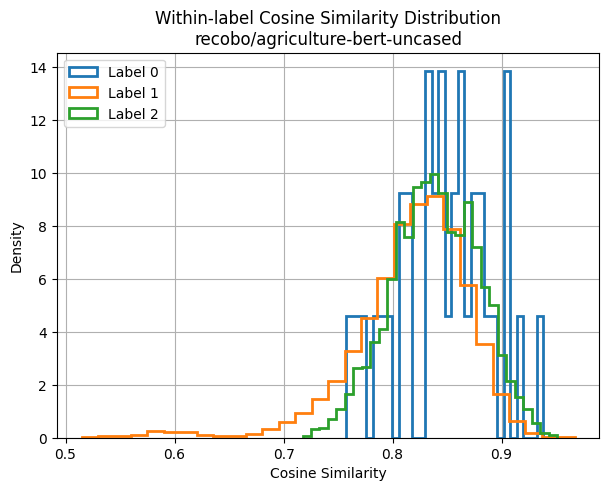

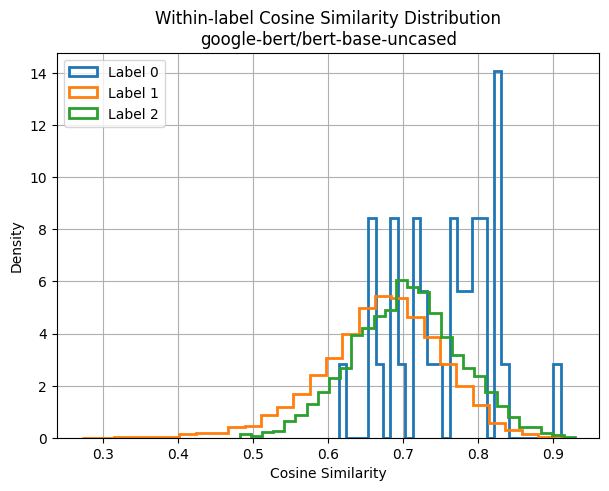

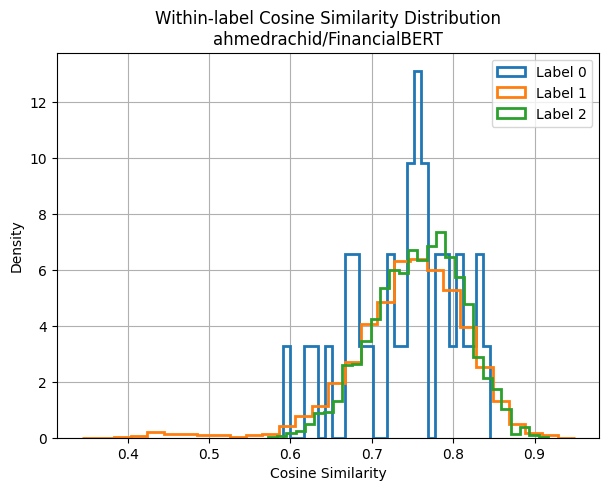

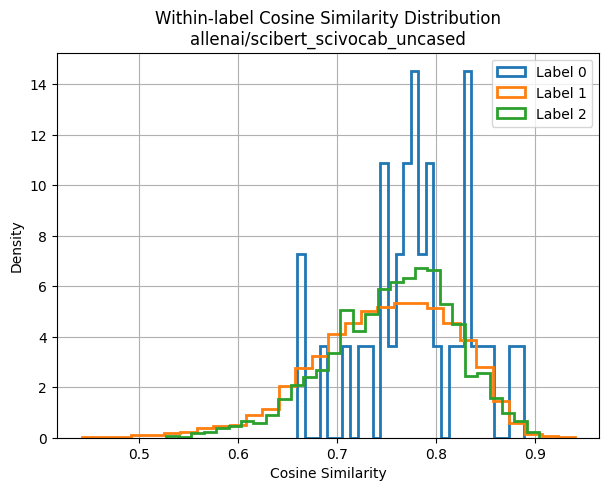

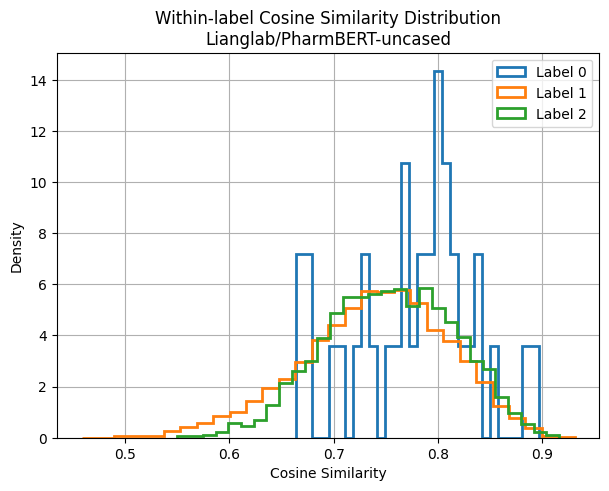

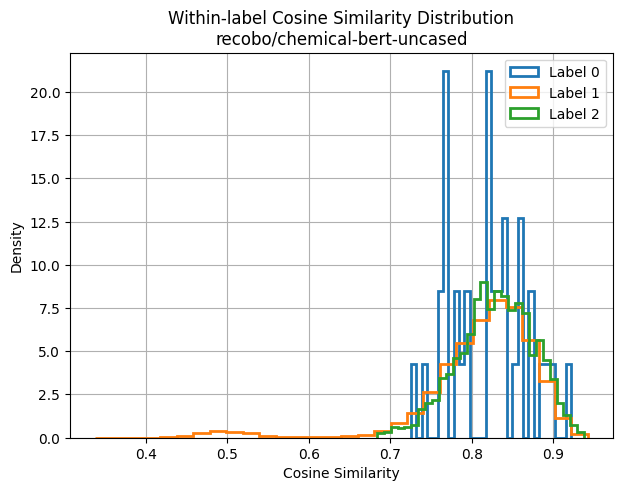

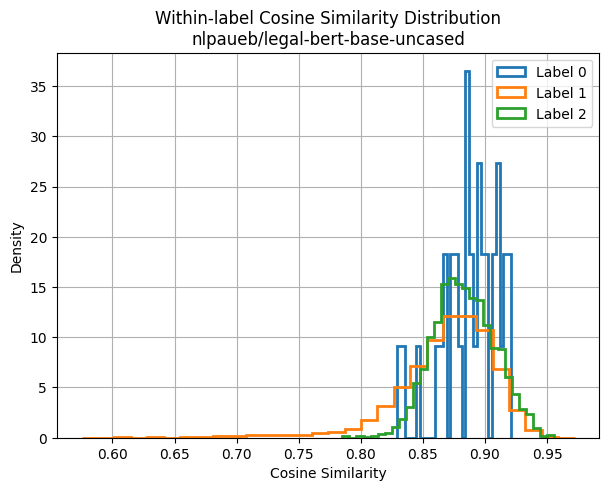

In [37]:
model_order = [
    "recobo/agriculture-bert-uncased",
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "allenai/scibert_scivocab_uncased",
    "Lianglab/PharmBERT-uncased",
    "recobo/chemical-bert-uncased",
    "nlpaueb/legal-bert-base-uncased"
]

plot_each_model_label_distributions(
    label_dist_df=label_dist_df,
    model_order=model_order,
    repetition=1,
    bins=30
)

In [38]:
def plot_combined_distribution_for_each_model(
    label_dist_df,
    model_order,
    repetition=None,
    bins=30,
    model_name_map=None
):
    """
    Plot one figure per model.
    For each model, combine cosine similarities from all labels
    into one single distribution.
    """

    for model_name in model_order:
        df_plot = label_dist_df[label_dist_df["model"] == model_name].copy()

        if repetition is not None:
            df_plot = df_plot[df_plot["repetition"] == repetition]

        if df_plot.empty:
            print(f"No data found for model: {model_name}")
            continue

        scores = df_plot["cosine_similarity"]

        if model_name_map is not None:
            display_name = model_name_map.get(model_name, model_name)
        else:
            display_name = model_name

        plt.figure(figsize=(7, 5))
        plt.hist(
            scores,
            bins=bins,
            density=True
        )

        plt.title(f"Combined Within-label Cosine Similarity Distribution\n{display_name}")
        plt.xlabel("Cosine Similarity")
        plt.ylabel("Density")
        plt.grid(True)
        plt.show()

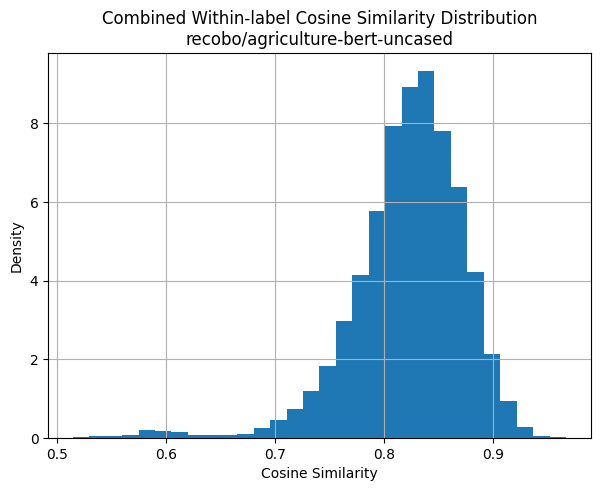

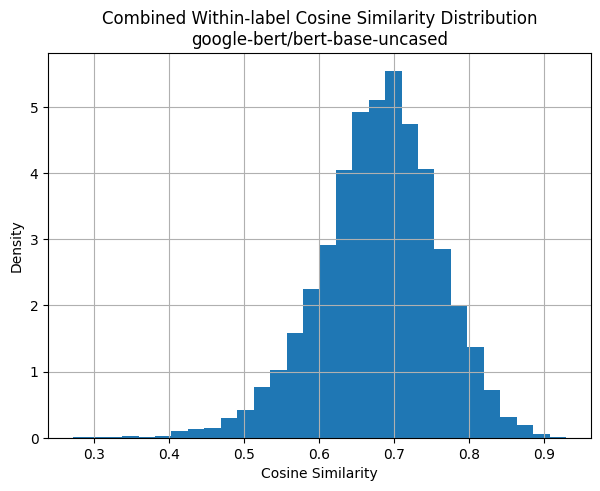

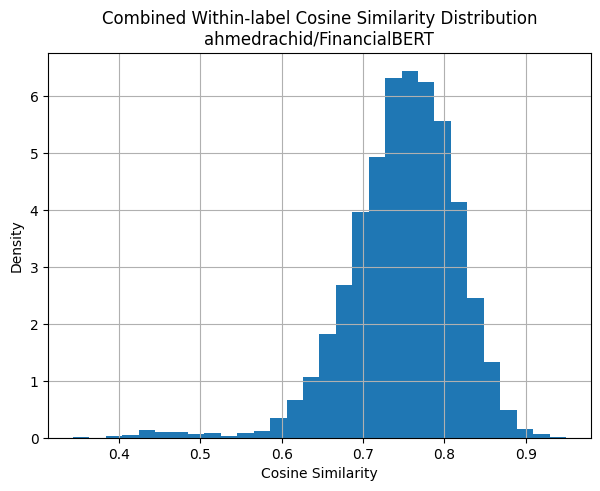

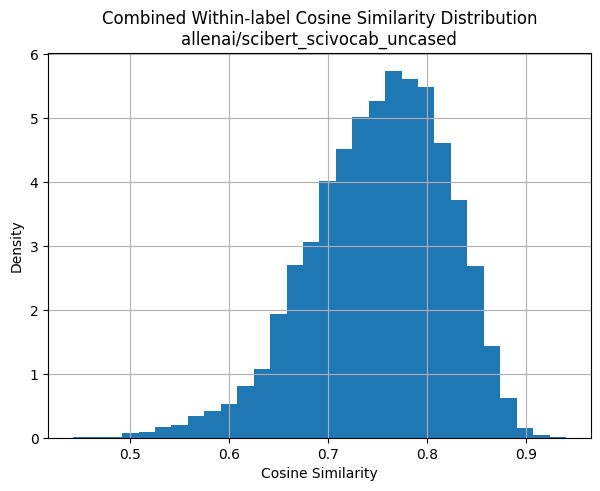

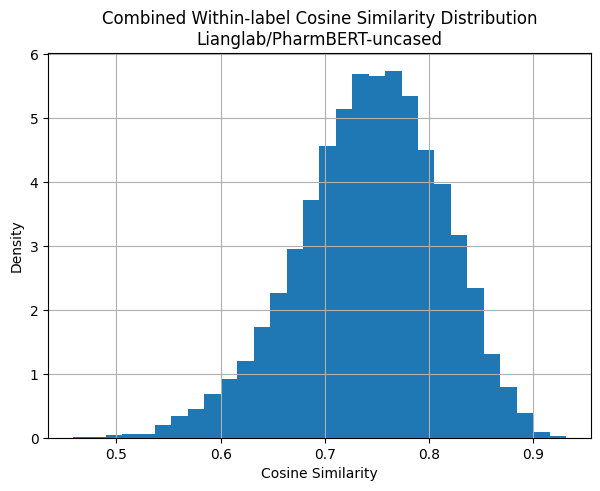

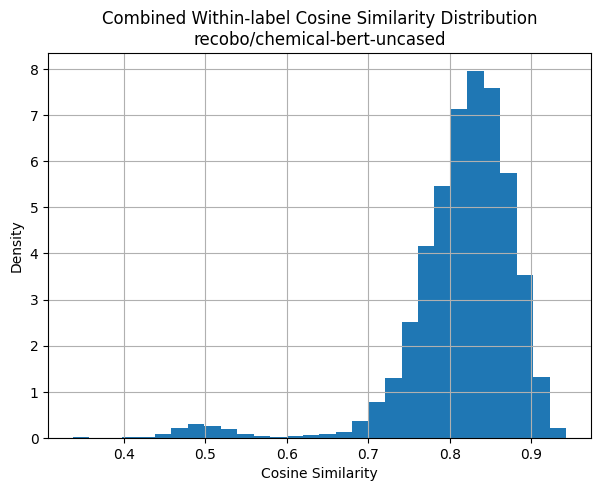

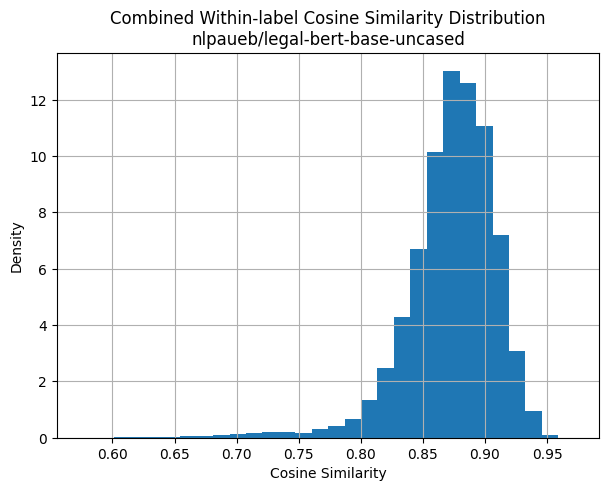

In [39]:
plot_combined_distribution_for_each_model(
    label_dist_df=label_dist_df,
    model_order=model_order,
    repetition=1,
    bins=30
)

In [40]:
def build_overall_eta_results(label_dist_df):
    group_cols = ["model"]

    if "repetition" in label_dist_df.columns:
        group_cols.append("repetition")

    if "random_seed" in label_dist_df.columns:
        group_cols.append("random_seed")

    if "sample_size" in label_dist_df.columns:
        group_cols.append("sample_size")

    results = []

    for keys, group in label_dist_df.groupby(group_cols):
        scores = group["cosine_similarity"].dropna().values

        if len(scores) == 0:
            continue

        if not isinstance(keys, tuple):
            keys = (keys,)

        row = dict(zip(group_cols, keys))

        mean_cosine = np.mean(scores)
        eta = asymmetry_eta(scores)

        row.update({
            "mean": mean_cosine,
            "eta": eta,
            "abs_eta": abs(eta),
            "n_pairs": len(scores)
        })

        results.append(row)

    return pd.DataFrame(results)

In [41]:
result_sizes_eta = build_overall_eta_results(label_dist_df)
result_sizes_eta

,model,repetition,random_seed,sample_size,mean,eta,abs_eta,n_pairs
0,Lianglab/PharmBERT-uncased,1,795,200,0.742985,-0.172755,0.172755,9763
1,Lianglab/PharmBERT-uncased,2,245,200,0.738161,-0.331752,0.331752,8428
2,Lianglab/PharmBERT-uncased,3,401,200,0.743480,-0.188304,0.188304,9321
3,ahmedrachid/FinancialBERT,1,795,200,0.748860,-0.203545,0.203545,9763
4,ahmedrachid/FinancialBERT,2,245,200,0.751482,-0.090334,0.090334,8428
5,ahmedrachid/FinancialBERT,3,401,200,0.750510,-0.198007,0.198007,9321
6,allenai/scibert_scivocab_uncased,1,795,200,0.750707,-0.296261,0.296261,9763
7,allenai/scibert_scivocab_uncased,2,245,200,0.757071,-0.341263,0.341263,8428
8,allenai/scibert_scivocab_uncased,3,401,200,0.761466,-0.399892,0.399892,9321
9,google-bert/bert-base-uncased,1,795,200,0.679941,-0.125354,0.125354,9763


In [42]:
eta_summary_df = result_sizes_eta.groupby("model").agg(
    mean=("mean", "mean"),
    mean_std=("mean", "std"),
    eta=("eta", "mean"),
    eta_std=("eta", "std"),
    abs_eta=("abs_eta", "mean"),
    abs_eta_std=("abs_eta", "std"),
    n_pairs=("n_pairs", "mean")
).reset_index()

eta_summary_df

,model,mean,mean_std,eta,eta_std,abs_eta,abs_eta_std,n_pairs
0,Lianglab/PharmBERT-uncased,0.741542,0.002939,-0.230937,0.087654,0.230937,0.087654,9170.666667
1,ahmedrachid/FinancialBERT,0.750284,0.001326,-0.163962,0.063824,0.163962,0.063824,9170.666667
2,allenai/scibert_scivocab_uncased,0.756415,0.005409,-0.345806,0.051964,0.345806,0.051964,9170.666667
3,google-bert/bert-base-uncased,0.682140,0.005984,-0.063511,0.059084,0.063511,0.059084,9170.666667
4,nlpaueb/legal-bert-base-uncased,0.873367,0.000889,-0.262705,0.043567,0.262705,0.043567,9170.666667
5,recobo/agriculture-bert-uncased,0.826999,0.005718,-0.209905,0.085116,0.209905,0.085116,9170.666667
6,recobo/chemical-bert-uncased,0.819050,0.004270,-0.428471,0.089297,0.428471,0.089297,9170.666667


Model Performance Ranking （In paper)

| Rank | Model | Accuracy / Micro F1 | Macro F1 | LMDFit Group |
|---:|---|---:|---:|---|
| 1 | AgricultureBERT | 0.844 | 0.830 | more-fit |
| 2 | BERT | 0.840 | 0.825 | more-fit |
| 3 | FinancialBERT | 0.841 | 0.824 | more-fit |
| 4 | SciBERT | 0.840 | 0.823 | less-fit |
| 5 | PharmBERT | 0.835 | 0.810 | more-fit |
| 6 | ChemicalBERT | 0.729 | 0.592 | less-fit |
| 7 | LegalBERT | 0.731 | 0.576 | less-fit |

## Observation: Global Cosine Similarity Distribution and Model Fitness

From the cosine similarity distribution plots, the best downstream model does not necessarily produce the most Gaussian-like or most symmetric global distribution.

BERT produces the most symmetric distribution, with Eta close to 0 and a relatively moderate mean cosine similarity. Its downstream performance is also strong, which partly supports the assumption that a more symmetric similarity distribution may indicate better model fitness.

However, AgricultureBERT achieves the best Macro F1 score, even though its cosine similarity distribution is not the most Gaussian-like. Its distribution is more concentrated and shifted to the right, with a higher mean cosine similarity. This suggests that global distributional symmetry alone is not sufficient to explain downstream classification performance.

In contrast, LegalBERT and ChemicalBERT show distributions that are highly concentrated toward high cosine similarity values. This means that many text pairs are represented as overly similar in the embedding space. Their downstream Macro F1 scores are also relatively low, which supports the paper's assumption that a cosine similarity distribution with a mean closer to 1 may indicate weaker discriminative ability.

Overall, the results suggest that Eta can be useful as an asymmetry descriptor, but it should not be used alone as a complete fitness indicator. Model fitness for text classification depends not only on the global shape of the cosine similarity distribution, but also on whether the model embeddings can separate different classes effectively.

Therefore, global Eta partially reflects model fitness, but it has limitations. A possible future improvement is to move from global cosine similarity distribution analysis to class-aware analysis, such as comparing intra-class and inter-class cosine similarity distributions.

## 5.0 Model Clustering

Mean cosine similarity measures the average closeness among all text embeddings generated by a model.

If the mean is too high, many texts are mapped very close to each other in the embedding space. This suggests that the model may not differentiate text samples well, making downstream classification harder.

Therefore, following the paper's assumption, a higher mean cosine similarity is treated as a penalty for model fitness.

<b> Higher mean value have to be punished more, but it's hard to decide the punishment, based on financial dataset, the best model architecture it actually have a relatively high mean value.</b>

In [47]:
def cluster_models_eta_2groups(results_df):
    results_df = results_df.copy()

    data = results_df[["eta", "mean"]].values

    labels = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    ).fit_predict(data)

    results_df["cluster"] = labels

    # Calculate average absolute eta for each cluster
    cluster_eta_score = results_df.groupby("cluster")["eta"].mean().abs()

    # Sort clusters: closest to 0 = high-fit
    ordered_clusters = cluster_eta_score.sort_values().index.tolist()

    cluster_name_map = {
        ordered_clusters[0]: "high-fit",
        ordered_clusters[1]: "less-fit"
    }

    results_df["fit_group"] = results_df["cluster"].map(cluster_name_map)

    return results_df

In [48]:
clustered_df_eta = cluster_models_eta_2groups(eta_summary_df)
clustered_df_eta

,model,mean,mean_std,eta,eta_std,abs_eta,abs_eta_std,n_pairs,cluster,fit_group
0,Lianglab/PharmBERT-uncased,0.741542,0.002939,-0.230937,0.087654,0.230937,0.087654,9170.666667,1,high-fit
1,ahmedrachid/FinancialBERT,0.750284,0.001326,-0.163962,0.063824,0.163962,0.063824,9170.666667,1,high-fit
2,allenai/scibert_scivocab_uncased,0.756415,0.005409,-0.345806,0.051964,0.345806,0.051964,9170.666667,0,less-fit
3,google-bert/bert-base-uncased,0.682140,0.005984,-0.063511,0.059084,0.063511,0.059084,9170.666667,1,high-fit
4,nlpaueb/legal-bert-base-uncased,0.873367,0.000889,-0.262705,0.043567,0.262705,0.043567,9170.666667,0,less-fit
5,recobo/agriculture-bert-uncased,0.826999,0.005718,-0.209905,0.085116,0.209905,0.085116,9170.666667,1,high-fit
6,recobo/chemical-bert-uncased,0.819050,0.004270,-0.428471,0.089297,0.428471,0.089297,9170.666667,0,less-fit


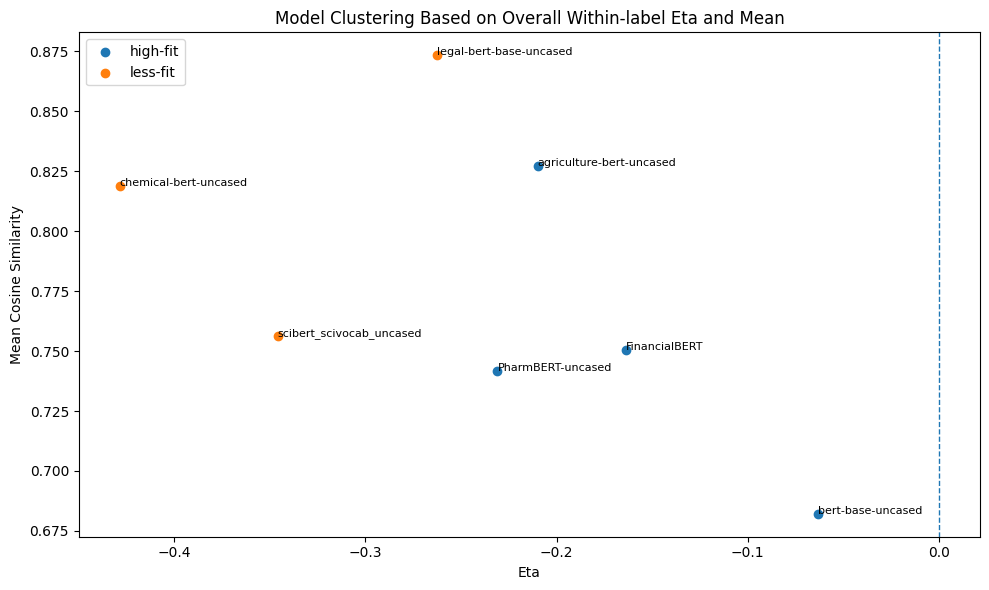

In [49]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))

for group in ["high-fit", "less-fit"]:
    sub = clustered_df_eta[clustered_df_eta["fit_group"] == group]

    if sub.empty:
        continue

    plt.scatter(
        sub["eta"],
        sub["mean"],
        label=group
    )

    for _, row in sub.iterrows():
        name = row["model"].split("/")[-1]

        plt.annotate(
            name,
            (row["eta"], row["mean"]),
            fontsize=8
        )

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Eta")
plt.ylabel("Mean Cosine Similarity")
plt.title("Model Clustering Based on Overall Within-label Eta and Mean")
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
valid_model_order = [
    model for model in model_order
    if model in clustered_df_eta["model"].values
]

ordered_eta_table = (
    clustered_df_eta
    .set_index("model")
    .loc[valid_model_order]
    .reset_index()
)

ordered_eta_table = ordered_eta_table[
    ["model", "mean", "eta", "abs_eta", "fit_group"]
]

ordered_eta_table

,model,mean,eta,abs_eta,fit_group
0,recobo/agriculture-bert-uncased,0.826999,-0.209905,0.209905,high-fit
1,google-bert/bert-base-uncased,0.682140,-0.063511,0.063511,high-fit
2,ahmedrachid/FinancialBERT,0.750284,-0.163962,0.163962,high-fit
3,allenai/scibert_scivocab_uncased,0.756415,-0.345806,0.345806,less-fit
4,Lianglab/PharmBERT-uncased,0.741542,-0.230937,0.230937,high-fit
5,recobo/chemical-bert-uncased,0.819050,-0.428471,0.428471,less-fit
6,nlpaueb/legal-bert-base-uncased,0.873367,-0.262705,0.262705,less-fit
